In [14]:
import pandas as pd
import os

xls = pd.ExcelFile('data/Cópia de Status_Servidor_LOCUS.xlsx')
print("Sheet names:", xls.sheet_names)
for sheet in xls.sheet_names:
    df = pd.read_excel('data/Cópia de Status_Servidor_LOCUS.xlsx', sheet_name=sheet)
    print(f"\n--- Sheet: {sheet} (shape: {df.shape}) ---")
    print(df.head(10))
    print(df.info())

Sheet names: ['RESERVA GPU']

--- Sheet: RESERVA GPU (shape: (53, 8)) ---
  Nome do responsável pela reserva             Máquina@IP  Quantidade de GPUs  \
0                     Filipe Moura  Netuno@150.164.214.40                 1.0   
1                           Carlos  Netuno@150.164.214.40                 1.0   
2                           Carlos  Netuno@150.164.214.40                 1.0   
3                   Flávio Soriano  Netuno@150.164.214.40                 1.0   
4                           Carlos  Netuno@150.164.214.40                 1.0   
5                   Flávio Soriano  Netuno@150.164.214.40                 1.0   
6                           Carlos  Netuno@150.164.214.40                 1.0   
7                     Filipe Moura  Netuno@150.164.214.40                 1.0   
8                   Kenia Carolina  Netuno@150.164.214.40                 1.0   
9                     Filipe Moura  Netuno@150.164.214.40                 1.0   

  Data e Hora de Início Data e Hor

In [16]:
df = df[df["Data e Hora de Início"].notna() & df["Data e Hora de Término"].notna()]

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 46 entries, 0 to 52
Data columns (total 8 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Nome do responsável pela reserva  46 non-null     object 
 1   Máquina@IP                        46 non-null     object 
 2   Quantidade de GPUs                42 non-null     float64
 3   Data e Hora de Início             46 non-null     object 
 4   Data e Hora de Término            46 non-null     object 
 5   Status da alocação                45 non-null     object 
 6   Informou no canal do WhatsApp?    40 non-null     object 
 7   Observações                       10 non-null     object 
dtypes: float64(1), object(7)
memory usage: 3.2+ KB


In [18]:
import datetime
import re
import numpy as np
import pandas as pd

def parse_dt_corrigido(val):
    if pd.isna(val):
        return pd.NaT
    if isinstance(val, (pd.Timestamp, datetime.datetime, datetime.date, np.datetime64)):
        return pd.to_datetime(val)
    
    s = str(val).strip()
    # Cobre "DD/MM/YYYY HHh", "DD/MM/YYYY HHhMM" e "DD/MM/YYYY HH:MMh"
    m = re.match(r'^(\d{2}/\d{2}/\d{4})\s+(\d{1,2})[:h](\d{2})?h?$', s)
    if m:
        date_part, hour_part, min_part = m.groups()
        h = int(hour_part)
        mi = int(min_part) if min_part else 0
        dt = pd.to_datetime(date_part, format='%d/%m/%Y')
        return dt + pd.Timedelta(hours=h, minutes=mi)
        
    return pd.to_datetime(s, dayfirst=True, errors='coerce')

df['inicio'] = df['Data e Hora de Início'].apply(parse_dt_corrigido)
df['termino'] = df['Data e Hora de Término'].apply(parse_dt_corrigido)
df['duracao_dias'] = (df['termino'] - df['inicio']).dt.total_seconds() / 86400.0

print(df[['Nome do responsável pela reserva', 'Máquina@IP', 'Quantidade de GPUs', 'inicio', 'termino', 'duracao_dias', 'Status da alocação']].to_string())
print("\nResumo numérico de duração (dias):")
print(df['duracao_dias'].describe())
print("\nMáquinas:", df['Máquina@IP'].value_counts(dropna=False))
print("\nStatus:", df['Status da alocação'].value_counts(dropna=False))
print("\nWhatsApp:", df['Informou no canal do WhatsApp?'].value_counts(dropna=False))
print("\nUsuários únicos:", df['Nome do responsável pela reserva'].nunique())

   Nome do responsável pela reserva             Máquina@IP  Quantidade de GPUs              inicio             termino  duracao_dias  Status da alocação
0                      Filipe Moura  Netuno@150.164.214.40                 1.0 2025-05-31 14:00:00 2025-06-02 10:00:00      1.833333           Concluído
1                            Carlos  Netuno@150.164.214.40                 1.0 2025-05-24 16:00:00 2025-05-25 23:00:00      1.291667           Concluído
2                            Carlos  Netuno@150.164.214.40                 1.0 2025-05-29 08:00:00 2025-05-30 13:00:00      1.208333           Concluído
3                    Flávio Soriano  Netuno@150.164.214.40                 1.0 2025-06-03 22:00:00 2025-06-04 22:00:00      1.000000           Concluído
4                            Carlos  Netuno@150.164.214.40                 1.0 2025-06-07 08:00:00 2025-06-08 23:00:00      1.625000           Concluído
5                    Flávio Soriano  Netuno@150.164.214.40                 1.0 202

In [36]:
df['Nome do responsável pela reserva'].value_counts()

Nome do responsável pela reserva
Filipe Moura       6
Carlos             5
Flávio Soriano     4
Kênia              4
Murilo Urquiza     4
Jessica            3
Gabriel Gravina    3
Sophia Serafim     2
Lívia Caroline     2
Lucas Felix        2
Flavio             2
Victor Martins     2
Kenia Carolina     2
Gabriel Martins    1
Igor/Alexandre     1
Alexandre          1
Daniel             1
Igor               1
Name: count, dtype: int64

Usuários únicos normalizados: 16
usuario
Filipe Moura       6
Flávio Soriano     6
Kênia              6
Carlos             5
Murilo Urquiza     4
Jessica            3
Gabriel Gravina    3
Victor Martins     2
Lívia Caroline     2
Sophia Serafim     2
Lucas Felix        2
Gabriel Martins    1
Igor               1
Igor/Alexandre     1
Alexandre          1
Daniel             1
Name: count, dtype: int64

Resumo Mensal:
         qtd_reservas  dias_reservados  media_duracao
mes                                                  
2025-05             3         4.333333       1.444444
2025-06             5         9.791667       1.958333
2025-07             2         4.666667       2.333333
2025-10             1         2.374306       2.374306
2025-11             6        16.440278       2.740046
2025-12             1         2.583333       2.583333
2026-01             1        31.000000      31.000000
2026-03             3        10.000000       3.333333
2026-04             1         5.000000   

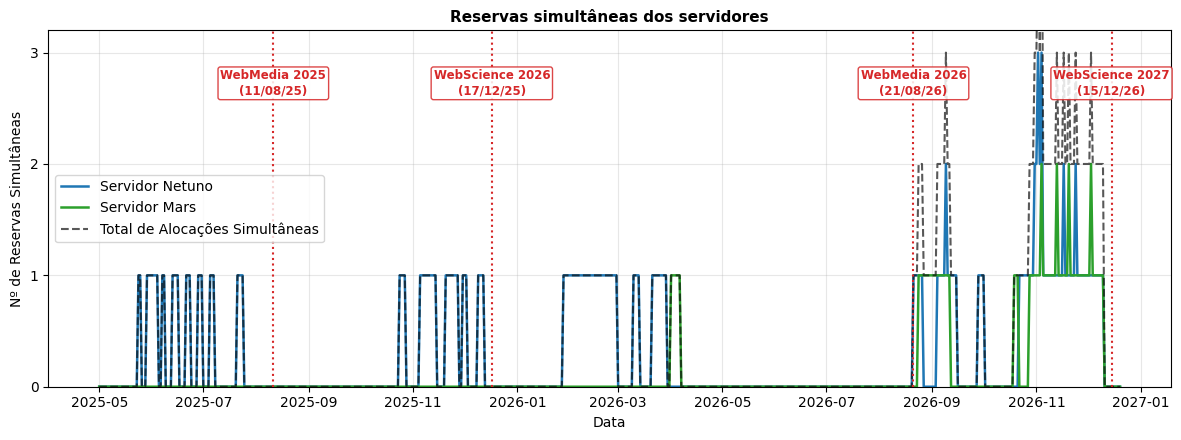

In [30]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_clean = df.copy()

# Clean names for counting users properly
df_clean['usuario'] = df_clean['Nome do responsável pela reserva'].str.strip().replace({
    'Kenia Carolina': 'Kênia',
    'Flavio': 'Flávio Soriano'
})
print("Usuários únicos normalizados:", df_clean['usuario'].nunique())
print(df_clean['usuario'].value_counts())

# Filter valid dates
valid = df_clean.dropna(subset=['inicio']).copy()
valid['termino_est'] = valid['termino'].fillna(valid['inicio'] + pd.Timedelta(days=3))

# Create daily time series of concurrent reservations from May 2025 to Dec 2026
date_range = pd.date_range(start='2025-05-01', end='2026-12-20', freq='D')
ts = pd.DataFrame(index=date_range)
ts['reservas_ativas'] = 0
ts['netuno'] = 0
ts['mars'] = 0

for idx, row in valid.iterrows():
    if row['Status da alocação'] == 'Cancelado':
        continue
    mask = (ts.index >= row['inicio'].floor('D')) & (ts.index <= row['termino_est'].floor('D'))
    ts.loc[mask, 'reservas_ativas'] += 1
    if 'Netuno' in str(row['Máquina@IP']):
        ts.loc[mask, 'netuno'] += 1
    elif 'Mars' in str(row['Máquina@IP']):
        ts.loc[mask, 'mars'] += 1

# Monthly aggregation of started reservations and total reserved GPU-days
valid['mes'] = valid['inicio'].dt.to_period('M')
monthly = valid[valid['Status da alocação'] != 'Cancelado'].groupby('mes').agg(
    qtd_reservas=('usuario', 'count'),
    dias_reservados=('duracao_dias', 'sum'),
    media_duracao=('duracao_dias', 'mean')
)
print("\nResumo Mensal:")
print(monthly.to_string())

# Deadlines
deadlines = {
    'WebMedia 2025\n(11/08/25)': pd.Timestamp('2025-08-11'),
    'WebScience 2026\n(17/12/25)': pd.Timestamp('2025-12-17'),
    'WebMedia 2026\n(21/08/26)': pd.Timestamp('2026-08-21'),
    'WebScience 2027\n(15/12/26)': pd.Timestamp('2026-12-15'),
}

# Check activity 30 days before each deadline vs outside
for name, d in deadlines.items():
    win_start = d - pd.Timedelta(days=30)
    in_win = valid[(valid['inicio'] > win_start) & (valid['inicio'] < d)]
    print(f"\nJanela 30d antes de {name.replace(chr(10), ' ')}: {len(in_win)} reservas iniciadas")
    if len(in_win) > 0:
        print(in_win[['usuario', 'Máquina@IP', 'inicio', 'termino', 'duracao_dias', 'Status da alocação']])

# Plot time series
plt.figure(figsize=(12, 4.5))
plt.plot(ts.index, ts['netuno'], label='Servidor Netuno', color='#1f77b4', linewidth=1.8)
plt.plot(ts.index, ts['mars'], label='Servidor Mars', color='#2ca02c', linewidth=1.8)
plt.plot(ts.index, ts['reservas_ativas'], label='Total de Alocações Simultâneas', color='#111111', linestyle='--', alpha=0.7)

for label, dt in deadlines.items():
    plt.axvline(dt, color='#d62728', linestyle=':', linewidth=1.5)
    plt.text(dt, 2.85, label, color='#d62728', fontsize=8.5, ha='center', va='top', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#d62728', alpha=0.85))

plt.title('Reservas simultâneas dos servidores', fontsize=11, fontweight='bold')
plt.ylabel('Nº de Reservas Simultâneas')
plt.xlabel('Data')
plt.ylim(0, 3.2)
plt.yticks([0, 1, 2, 3])
plt.grid(True, alpha=0.3)
plt.legend(loc="center left")
plt.tight_layout()
plt.savefig('images/comportamento_temporal_gpu.pdf')

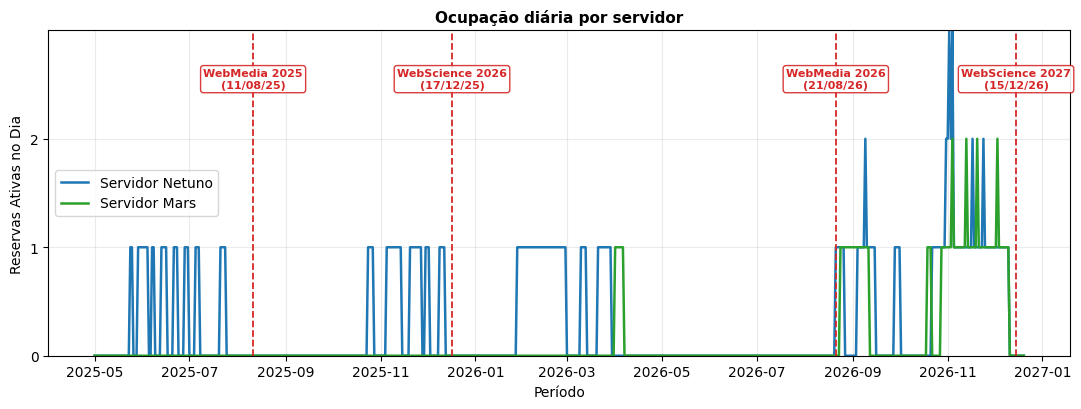

In [29]:
plt.figure(figsize=(11, 4.2))
plt.plot(ts.index, ts['netuno'], label='Servidor Netuno', color='#1f77b4', linewidth=1.8)
plt.plot(ts.index, ts['mars'], label='Servidor Mars', color='#2ca02c', linewidth=1.8)

deadlines_clean = [
    ('WebMedia 2025\n(11/08/25)', pd.Timestamp('2025-08-11'), 2.55),
    ('WebScience 2026\n(17/12/25)', pd.Timestamp('2025-12-17'), 2.55),
    ('WebMedia 2026\n(21/08/26)', pd.Timestamp('2026-08-21'), 2.55),
    ('WebScience 2027\n(15/12/26)', pd.Timestamp('2026-12-15'), 2.55),
]

for label, dt, y_pos in deadlines_clean:
    plt.axvline(dt, color='#d62728', linestyle='--', linewidth=1.3)
    plt.text(dt, y_pos, label, color='#d62728', fontsize=8, ha='center', va='center', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#d62728', alpha=0.9))

plt.title('Ocupação diária por servidor', fontsize=11, fontweight='bold')
plt.ylabel('Reservas Ativas no Dia')
plt.xlabel('Período')
plt.ylim(0, 3.0)
plt.yticks([0, 1, 2])
plt.grid(True, alpha=0.25)
plt.legend(loc="center left")
plt.tight_layout()
plt.savefig('images/ocupacao_servidores_gpu.pdf')